# Exploratory Data Analysis of the Synthetic Injection Pump Dataset

## Objective

Understand the structure, quality, temporal behavior, operating states, and failure patterns of the 15-day synthetic dataset before training a machine-learning model.

This notebook reviews:

- Dataset dimensions, columns, and data types.
- Missing values, duplicates, timestamps, and sampling frequency.
- Pump operating states, alarms, and trips.
- Failure-class and event distributions.
- Sensor statistics and physical behavior.
- Relationships between sensors and failure modes.
- Data-leakage risks and recommendations for modeling.

> This dataset is synthetic. Its patterns are suitable for developing and demonstrating the analytical workflow, but a production model must be validated with real field data.

## 0. Import the required libraries

The following libraries are used for data manipulation, visualization, and statistical analysis. Display settings are adjusted to make wide tables easier to inspect.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid")

Path.cwd()

PosixPath('/home/cristian/proyectos/mantenimiento-ia/notebooks')

## 1. Locate the project files

The notebook may be opened from the project root or from the `notebooks` directory. This cell detects the project root and defines the paths to the definitive CSV dataset and its validation report.

In [2]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "dataset_definitivo_15d"
DATA_PATH = DATA_DIR / "dataset_bomba_inyeccion.csv"
REPORT_PATH = DATA_DIR / "informe_validacion.json"

print(f"Project root: {PROJECT_ROOT.resolve()}")
print(f"Dataset exists: {DATA_PATH.exists()} | {DATA_PATH.resolve()}")
print(f"Report exists:  {REPORT_PATH.exists()} | {REPORT_PATH.resolve()}")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

Project root: /home/cristian/proyectos/mantenimiento-ia
Dataset exists: True | /home/cristian/proyectos/mantenimiento-ia/data/processed/dataset_definitivo_15d/dataset_bomba_inyeccion.csv
Report exists:  True | /home/cristian/proyectos/mantenimiento-ia/data/processed/dataset_definitivo_15d/informe_validacion.json


## 2. Review the generator validation report

The validation report provides an independent summary generated together with the dataset. It is useful for confirming the expected number of rows, date range, missing values, duplicate timestamps, alarms, trips, and normal-operation percentage.

In [3]:
validation_report = {}
if REPORT_PATH.exists():
    with REPORT_PATH.open(encoding="utf-8") as file:
        validation_report = json.load(file)

report_summary_keys = [
    "rows", "start", "end", "duplicate_timestamps",
    "missing_values", "chronological", "alarm_rows",
    "threshold_trip_rows", "simulated_trip_rows", "normal_rows_pct"
]

pd.Series(
    {key: validation_report.get(key) for key in report_summary_keys},
    name="Validation report"
).to_frame()

,Validation report
rows,1296000
start,2026-01-01 00:00:00
end,2026-01-15 23:59:59
duplicate_timestamps,0
missing_values,0
chronological,True
alarm_rows,107609
threshold_trip_rows,84416
simulated_trip_rows,29373
normal_rows_pct,83.602


### Validation Report Findings

The validation report confirms that the synthetic dataset contains **1,296,000 records**, corresponding to **15 continuous days** at a sampling interval of one second.

The dataset covers the period from **January 1, 2026 at 00:00:00** to **January 15, 2026 at 23:59:59**.

The basic data-quality checks produced satisfactory results:

* No duplicate timestamps were found.
* No missing values were found.
* All records are arranged in chronological order.
* Approximately **83.60%** of the records represent normal operating conditions.
* The remaining **16.40%** are associated with abnormal or failure conditions.

The report also distinguishes between alarms, trip thresholds, and executed trips:

* `alarm_rows` contains **107,609 records** in which at least one alarm condition was active.
* `threshold_trip_rows` contains **84,416 records** in which a sensor reached or exceeded a configured trip threshold. This represents a dangerous process condition, but it does not necessarily mean that the pump stopped immediately.
* `simulated_trip_rows` contains **29,373 records** associated with an executed trip sequence. During these periods, the protection acts and the simulated pump transitions toward a stopped condition.

The typical protection sequence is:

1. A sensor becomes abnormal.
2. The alarm threshold is reached.
3. The trip threshold is reached.
4. The trip is executed.
5. The pump stops and the process variables respond accordingly.

These categories may overlap. Therefore, their record counts should not be added together as if they represented independent groups.

Overall, the validation results indicate that the dataset has good structural quality and contains sufficient normal and abnormal operating periods for exploratory analysis and the development of a failure-classification model.


## 3. Load the definitive dataset

The CSV is loaded into a pandas DataFrame. `Timestamp` is parsed directly as a date-time variable to support temporal checks and plots.

In [4]:
df = pd.read_csv(DATA_PATH, parse_dates=["Timestamp"])

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:,.2f} MB")
df.head()

Rows: 1,296,000
Columns: 33
Memory usage: 383.04 MB


,Timestamp,Suction_Filter_DP,Suction_Pressure,Discharge_Pressure,Suction_Flow,Wellhead_Pressure,VFD_Frequency_Actual,Motor_Current,Pump_Running,Pump_Vibration_Free_End,Pump_Vibration_Coupling_End,Motor_Vibration_Free_End,Motor_Vibration_Coupling_End,Pump_Bearing_Temp_Free_End,Pump_Bearing_Temp_Coupling_End,Motor_Bearing_Temp_Free_End,Motor_Bearing_Temp_Coupling_End,Motor_Winding_Temp_1A,Motor_Winding_Temp_1B,Motor_Winding_Temp_2A,Motor_Winding_Temp_2B,Motor_Winding_Temp_3A,Motor_Winding_Temp_3B,Injection_Valve_Position,Operating_State,Failure_Code,Failure_Name,Fault_Subtype,Fault_Location,Severity,Alarm_Active,Trip_Active,Event_ID
0,2026-01-01 00:00:00,1.024,40.183,"1,309.767","6,015.239","1,264.590",49.525,201.919,1,0.033,0.033,0.030,0.033,91.234,89.834,90.035,92.400,95.836,97.599,91.027,95.500,93.754,95.605,54.159,Normal,0,Operación normal,No aplica,No aplica,0.000,0,0,0
1,2026-01-01 00:00:01,1.022,40.274,"1,308.926","6,012.572","1,263.700",49.525,201.398,1,0.036,0.039,0.032,0.033,91.177,89.788,89.995,92.344,95.756,97.509,90.963,95.417,93.678,95.528,54.159,Normal,0,Operación normal,No aplica,No aplica,0.000,0,0,0
2,2026-01-01 00:00:02,1.024,40.232,"1,308.641","6,012.986","1,263.652",49.527,201.013,1,0.031,0.032,0.031,0.037,91.136,89.753,89.958,92.308,95.700,97.447,90.913,95.364,93.626,95.463,54.163,Normal,0,Operación normal,No aplica,No aplica,0.000,0,0,0
3,2026-01-01 00:00:03,1.022,40.228,"1,308.566","6,014.080","1,263.456",49.531,201.129,1,0.030,0.031,0.030,0.034,91.149,89.770,89.976,92.318,95.716,97.456,90.944,95.376,93.648,95.484,54.171,Normal,0,Operación normal,No aplica,No aplica,0.000,0,0,0
4,2026-01-01 00:00:04,1.023,40.228,"1,308.548","6,012.028","1,263.400",49.532,200.702,1,0.030,0.031,0.028,0.032,91.101,89.730,89.942,92.278,95.644,97.387,90.890,95.316,93.588,95.421,54.173,Normal,0,Operación normal,No aplica,No aplica,0.000,0,0,0


## 4. Inspect columns and data types

This inspection separates timestamp, sensor, operating-state, event, and label variables. Correct data types are important because machine-learning models require numerical inputs, while identifiers and descriptive labels need special treatment.

In [5]:
column_summary = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str).values,
    "Unique values": [df[column].nunique(dropna=False) for column in df.columns]
})

column_summary

,Column,Data type,Unique values
0,Timestamp,datetime64[us],1296000
1,Suction_Filter_DP,float64,38002
2,Suction_Pressure,float64,388821
3,Discharge_Pressure,float64,1139515
4,Suction_Flow,float64,1234954
5,Wellhead_Pressure,float64,1082279
6,VFD_Frequency_Actual,float64,459476
7,Motor_Current,float64,1003229
8,Pump_Running,int64,2
9,Pump_Vibration_Free_End,float64,16385


### Findings: Columns and Data Types

The dataset contains **33 columns**, including the timestamp, physical sensor measurements, operating information, event identifiers, and failure labels.

The `Timestamp` column was correctly recognized as `datetime64`, allowing temporal operations such as duration calculations, chronological analysis, and time-based data splitting.

The physical sensor variables were recognized as `float64`. This is appropriate because pressure, flow, current, vibration, temperature, frequency, and valve-position measurements contain continuous decimal values.

The binary variables `Pump_Running`, `Alarm_Active`, and `Trip_Active` each contain two possible values:

* `0`: inactive, stopped, or false.
* `1`: active, running, or true.

The categorical and identification columns show the expected number of unique values:

* `Operating_State` contains eight operating states.
* `Failure_Code` and `Failure_Name` contain 16 classes: normal operation and 15 failure modes.
* `Event_ID` contains 151 values: `0` for records without an active failure event and identifiers `1–150` for the generated events.
* `Fault_Subtype` contains 11 categories.
* `Fault_Location` contains 17 locations or location combinations.

Most physical sensors contain many unique values. This is expected for continuous measurements that include process variation, noise, degradation, and recovery behavior.

No obvious data-type problems were identified. However, descriptive labels, event identifiers, alarms, trips, severity, and operating states must be excluded from the predictive input features because they could directly reveal the target and cause data leakage.


## 5. Check data quality and temporal consistency

This section checks missing values, fully duplicated rows, duplicate timestamps, invalid timestamps, chronological order, and sampling intervals. A one-second dataset should normally have a one-second difference between consecutive timestamps.

In [6]:
time_differences = df["Timestamp"].diff().dropna()

quality_summary = pd.Series({
    "Missing values": int(df.isna().sum().sum()),
    "Fully duplicated rows": int(df.duplicated().sum()),
    "Duplicate timestamps": int(df["Timestamp"].duplicated().sum()),
    "Invalid timestamps": int(df["Timestamp"].isna().sum()),
    "Chronological order": bool(df["Timestamp"].is_monotonic_increasing),
    "Start": df["Timestamp"].min(),
    "End": df["Timestamp"].max(),
    "Most common interval": time_differences.mode().iloc[0],
    "Unexpected intervals": int((time_differences != pd.Timedelta(seconds=1)).sum()),
}, name="Result")

quality_summary.to_frame()

,Result
Missing values,0
Fully duplicated rows,0
Duplicate timestamps,0
Invalid timestamps,0
Chronological order,True
Start,2026-01-01 00:00:00
End,2026-01-15 23:59:59
Most common interval,0 days 00:00:01
Unexpected intervals,0


### Findings: Data Quality and Temporal Consistency

The dataset passed all basic data-quality and temporal-consistency checks.

No missing values, fully duplicated rows, duplicate timestamps, or invalid timestamps were detected. Therefore, no removal or imputation is required at this stage.

The records are correctly arranged in chronological order and cover the complete period from **January 1, 2026 at 00:00:00** to **January 15, 2026 at 23:59:59**.

The most common interval between consecutive records is exactly **one second**. Additionally, no unexpected intervals were detected, confirming that the dataset has a continuous and regular sampling frequency without temporal gaps.

This temporal consistency is important for time-series analysis, the calculation of rolling-window features, event detection, and the future creation of training, validation, and test sets based on temporal blocks.

## 6. Analyze pump operating states

`Pump_Running` indicates whether the pump is running (`1`) or stopped (`0`). If `Operating_State` is available, it provides more detailed stages such as normal operation, degradation, trip, stop, startup, and recovery.

In [7]:
pump_status = (
    df["Pump_Running"]
    .value_counts()
    .sort_index()
    .rename_axis("Pump_Running")
    .reset_index(name="Records")
)
pump_status["Status"] = pump_status["Pump_Running"].map({0: "Stopped", 1: "Running"})
pump_status["Percentage"] = pump_status["Records"].div(len(df)).mul(100).round(2)

display(pump_status[["Status", "Records", "Percentage"]])

if "Operating_State" in df.columns:
    operating_states = (
        df["Operating_State"].value_counts().rename_axis("State").reset_index(name="Records")
    )
    operating_states["Percentage"] = operating_states["Records"].div(len(df)).mul(100).round(2)
    display(operating_states)

,Status,Records,Percentage
0,Stopped,51153,3.950
1,Running,1244847,96.050


,State,Records,Percentage
0,Normal,1037516,80.060
1,Fault,108838,8.400
2,Degrading,74313,5.730
3,Tripped,29373,2.270
4,Stopped,21600,1.670
5,Starting,17880,1.380
6,Recovering,6120,0.470
7,Stopping,360,0.030


### Findings: Pump Operating States

The pump was running for **1,244,847 records**, representing **96.05%** of the dataset. It was stopped for **51,153 records**, equivalent to **3.95%**.

The detailed operating-state distribution shows that **80.06%** of the records correspond to stable normal operation. However, the pump can remain running during abnormal states:

- `Degrading` represents **5.73%** of the records and describes the transition from normal operation toward a failure.
- `Fault` represents **8.40%** and indicates that a failure condition is fully developed.
- `Tripped` represents **2.27%** and corresponds to periods when protection has operated.
- `Stopped` represents **1.67%** of the dataset.
- `Starting`, `Recovering`, and `Stopping` represent transitional operating stages.

`Pump_Running` and `Operating_State` provide different information. `Pump_Running` only indicates whether the pump is running or stopped, whereas `Operating_State` describes the specific condition or transition occurring at that time.

The presence of `Degrading` and `Fault` records while the pump is still running is especially valuable for predictive maintenance because it provides data that may allow a model to recognize abnormal behavior before a protective trip occurs.

During model development, stopped and transitional periods must be handled carefully. Their naturally low flow, current, frequency, and vibration values should not be incorrectly interpreted as failure signatures.

### Visualize pump operation over time

A one-day view makes operating cycles easier to interpret than plotting all 1.3 million records. The step plot shows transitions between running and stopped conditions.

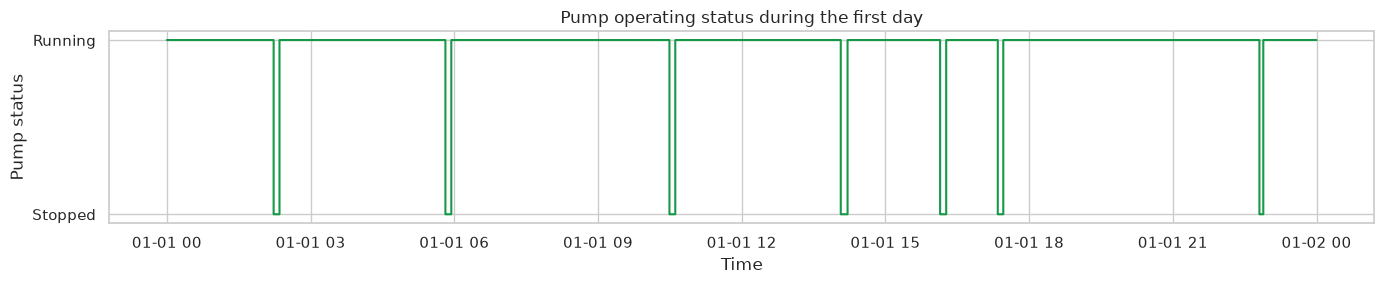

In [8]:
first_day_end = df["Timestamp"].min() + pd.Timedelta(days=1)
one_day = df.loc[df["Timestamp"] < first_day_end, ["Timestamp", "Pump_Running"]]

plt.figure(figsize=(14, 3))
plt.step(one_day["Timestamp"], one_day["Pump_Running"], where="post", color="#159947")
plt.yticks([0, 1], ["Stopped", "Running"])
plt.title("Pump operating status during the first day")
plt.xlabel("Time")
plt.ylabel("Pump status")
plt.tight_layout()
plt.show()

## 7. Analyze failure-class distribution

The number and percentage of records for each class reveal class imbalance. Accuracy alone can be misleading when normal operation is much more frequent than individual failures.

,Failure_Code,Failure_Name,Records,Percentage
0,0,Operación normal,1083476,83.602
1,1,Filtro de succión obstruido,16295,1.257
2,2,Baja presión de succión,12610,0.973
3,3,Alta presión de descarga,15606,1.204
4,4,Cavitación,13757,1.061
5,5,Sobrecarga del motor,14485,1.118
6,6,Falla de rodamiento,15462,1.193
7,7,Baja presión de descarga,13916,1.074
8,8,Alta temperatura de devanados,14526,1.121
9,9,Alta temperatura de rodamientos,12457,0.961


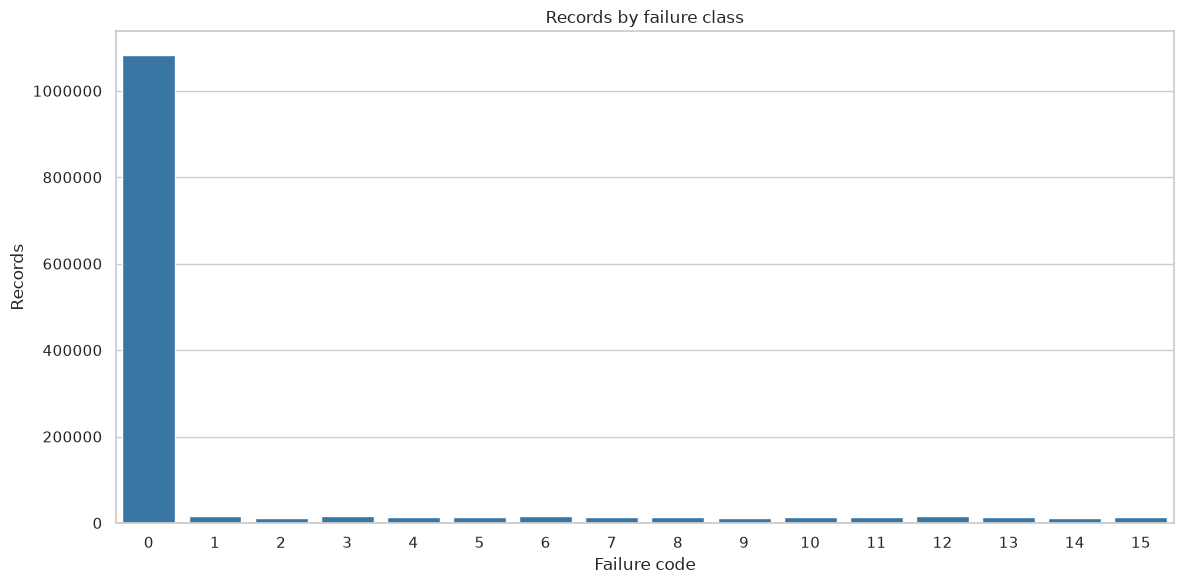

In [9]:
class_distribution = (
    df.groupby(["Failure_Code", "Failure_Name"], dropna=False)
    .size()
    .reset_index(name="Records")
    .sort_values("Failure_Code")
)
class_distribution["Percentage"] = (
    class_distribution["Records"].div(len(df)).mul(100).round(3)
)

display(class_distribution)

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=class_distribution, x="Failure_Code", y="Records", color="#2878B5")
ax.ticklabel_format(style="plain", axis="y")
plt.title("Records by failure class")
plt.xlabel("Failure code")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

### Findings: Failure-Class Distribution

Normal operation is the dominant class, with **1,083,476 records**, representing **83.602%** of the complete dataset.

The 15 failure classes contain **212,524 records in total**, corresponding to the remaining **16.398%**. Each individual failure class represents between approximately **0.84% and 1.26%** of the dataset.

Although there is a considerable imbalance between normal operation and failure conditions, the individual failure classes are relatively balanced with one another. The most frequent failure is `High motor current`, with 16,363 records, while the least frequent is `Low wellhead pressure or possible pipeline rupture`, with 10,922 records.

This class distribution has important implications for predictive modeling. A model that always predicts normal operation could achieve approximately **83.6% accuracy** without detecting any failure. Therefore, overall accuracy will not be sufficient to evaluate model performance.

The future model should be evaluated using:

- Recall for each failure class.
- Precision and F1-score.
- Macro-averaged F1-score.
- Balanced accuracy.
- A multiclass confusion matrix.

Class weighting or another imbalance-handling strategy may also be required. However, any resampling technique must be applied only to the training data and after separating complete failure events to prevent data leakage.

## 8. Analyze independent failure events

Rows from the same event are temporally related and should not be divided randomly across training and test sets. This section verifies the number of independent events per class and summarizes their duration and severity.

In [10]:
event_rows = df.loc[df["Event_ID"].fillna(0).ne(0)].copy()

events = (
    event_rows.groupby("Event_ID")
    .agg(
        Failure_Code=("Failure_Code", "first"),
        Failure_Name=("Failure_Name", "first"),
        Start=("Timestamp", "min"),
        End=("Timestamp", "max"),
        Records=("Timestamp", "size"),
        Severity=("Severity", "max"),
        Trip=("Trip_Active", "max"),
    )
    .reset_index()
)
events["Duration_minutes"] = (events["End"] - events["Start"]).dt.total_seconds().div(60).round(2)

events_by_class = (
    events.groupby(["Failure_Code", "Failure_Name"])
    .agg(Events=("Event_ID", "nunique"), Mean_duration_min=("Duration_minutes", "mean"), Trips=("Trip", "sum"))
    .reset_index()
)
events_by_class[["Mean_duration_min"]] = events_by_class[["Mean_duration_min"]].round(2)
events_by_class

,Failure_Code,Failure_Name,Events,Mean_duration_min,Trips
0,1,Filtro de succión obstruido,10,27.140,0
1,2,Baja presión de succión,10,21.000,10
2,3,Alta presión de descarga,10,25.990,10
3,4,Cavitación,10,22.910,5
4,5,Sobrecarga del motor,10,24.130,10
5,6,Falla de rodamiento,10,25.750,6
6,7,Baja presión de descarga,10,23.180,0
7,8,Alta temperatura de devanados,10,24.190,10
8,9,Alta temperatura de rodamientos,10,20.750,7
9,10,Alta vibración en bomba o motor,10,22.410,8


## Independent Failure Event Analysis

The dataset contains **150 independent failure events**, distributed evenly across the 15 failure classes. Each failure class contains exactly **10 events**.

This confirms that the dataset is balanced at the **event level**, even though the number of rows per failure class varies. The difference in row counts is mainly caused by the different event durations.

The mean event duration ranges from **18.19 minutes** for low wellhead pressure or possible pipeline rupture to **27.26 minutes** for high motor current.

The `Trips` column represents the number of events that contain at least one record where `Trip_Active = 1`. It does not represent the total number of rows with an active trip.

The trip behavior varies by failure type:

- Clogged suction filter and low discharge pressure produced no trips.
- Cavitation produced trips in 5 of 10 events.
- Bearing failure produced trips in 6 of 10 events.
- High bearing temperature produced trips in 7 of 10 events.
- High vibration produced trips in 8 of 10 events.
- The remaining failure classes produced trips in all 10 events.

This variation is useful because it represents different failure severities. Some faults generate an alarm or degradation without stopping the pump, while more critical faults trigger a protective shutdown.

### Machine-learning implication

The dataset should later be divided using complete `Event_ID` groups instead of randomly splitting individual rows. This prevents records from the same event from appearing in both the training and test datasets, which would cause **data leakage**.

Because every failure class contains 10 events, a possible stratified division is:

- 6 events per class for training
- 2 events per class for validation
- 2 events per class for testing

Normal operating periods should be divided separately using complete chronological time blocks.

## 9. Define sensor and metadata columns

Labels, identifiers, alarms, trips, and operating states describe the event or its outcome. They must be separated from the physical sensor measurements before statistical analysis and predictive modeling.

In [11]:
metadata_columns = {
    "Timestamp", "Failure_Code", "Failure_Name", "Event_ID",
    "Fault_Subtype", "Fault_Location", "Severity",
    "Alarm_Active", "Trip_Active", "Operating_State"
}

sensor_columns = [
    column for column in df.select_dtypes(include="number").columns
    if column not in metadata_columns and column != "Pump_Running"
]

print(f"Sensor variables: {len(sensor_columns)}")
sensor_columns

Sensor variables: 22


['Suction_Filter_DP',
 'Suction_Pressure',
 'Discharge_Pressure',
 'Suction_Flow',
 'Wellhead_Pressure',
 'VFD_Frequency_Actual',
 'Motor_Current',
 'Pump_Vibration_Free_End',
 'Pump_Vibration_Coupling_End',
 'Motor_Vibration_Free_End',
 'Motor_Vibration_Coupling_End',
 'Pump_Bearing_Temp_Free_End',
 'Pump_Bearing_Temp_Coupling_End',
 'Motor_Bearing_Temp_Free_End',
 'Motor_Bearing_Temp_Coupling_End',
 'Motor_Winding_Temp_1A',
 'Motor_Winding_Temp_1B',
 'Motor_Winding_Temp_2A',
 'Motor_Winding_Temp_2B',
 'Motor_Winding_Temp_3A',
 'Motor_Winding_Temp_3B',
 'Injection_Valve_Position']

## Sensor Variable Identification

The dataset contains **22 numerical sensor variables** representing the operating condition of the injection-pump system.

These variables can be organized into the following groups:

- **Hydraulic and process variables:** suction filter differential pressure, suction pressure, discharge pressure, suction flow, and wellhead pressure.
- **Pump and drive variables:** VFD frequency, motor current, and injection valve position.
- **Vibration variables:** vibration measurements at the free and coupling ends of the pump and motor.
- **Bearing temperature variables:** temperatures at the free and coupling ends of the pump and motor bearings.
- **Motor winding temperature variables:** temperatures from phases A and B across the three motor winding groups.

These variables will be used as **input features** for exploratory data analysis and machine-learning models. They provide information about the hydraulic, electrical, mechanical, and thermal behavior of the equipment.

The operating-state, alarm, trip, failure-label, timestamp, and event-identification columns are excluded from this sensor list because they describe the system condition or the prediction target rather than direct sensor measurements.

### Machine-learning implication

A predictive model can analyze patterns across these 22 sensor variables to identify normal operation, degradation, and different failure modes.

Before training a model, the variables should be evaluated for:

- Statistical distributions and operating ranges
- Correlation and redundancy
- Outliers and abnormal values
- Behavior during normal and failure periods
- Changes before alarms and protective trips
- Potential data leakage

## 10. Calculate descriptive statistics for sensors

Descriptive statistics help detect unusual ranges, low-variance variables, and extreme values. Fault values should not be removed automatically because they may represent the intended failure signature.

In [13]:
sensor_statistics = df[sensor_columns].describe().transpose()
sensor_statistics["missing"] = df[sensor_columns].isna().sum()
sensor_statistics["unique"] = df[sensor_columns].nunique()
sensor_statistics.round(3)

,count,mean,std,min,25%,50%,75%,max,missing,unique
Suction_Filter_DP,"1,296,000.000",1.018,0.144,0.937,0.982,1.006,1.017,3.000,0,38002
Suction_Pressure,"1,296,000.000",39.533,2.847,17.000,39.261,39.692,40.693,49.586,0,388821
Discharge_Pressure,"1,296,000.000","1,280.378",103.729,120.274,"1,271.903","1,300.076","1,308.162","1,480.000",0,1139515
Suction_Flow,"1,296,000.000","5,700.929","1,258.783",0.000,"5,721.053","6,042.907","6,133.158","8,350.000",0,1234954
Wellhead_Pressure,"1,296,000.000","1,241.003",103.321,120.000,"1,236.572","1,254.738","1,259.749","1,475.000",0,1082279
VFD_Frequency_Actual,"1,296,000.000",47.711,9.946,0.000,48.229,49.746,51.458,52.327,0,459476
Motor_Current,"1,296,000.000",195.831,44.763,0.000,194.033,201.737,209.266,365.000,0,1003229
Pump_Vibration_Free_End,"1,296,000.000",0.033,0.015,0.000,0.025,0.032,0.039,0.246,0,16385
Pump_Vibration_Coupling_End,"1,296,000.000",0.033,0.015,0.000,0.025,0.033,0.040,0.254,0,15778
Motor_Vibration_Free_End,"1,296,000.000",0.033,0.012,0.000,0.026,0.033,0.040,0.263,0,12238


## Descriptive Statistics of Sensor Variables

The descriptive analysis covers **1,296,000 observations** for each of the 22 sensor variables. No missing values were detected, confirming that the dataset is complete.

The quartiles show that most sensor measurements remain concentrated around their normal operating ranges. However, several maximum values are considerably higher than the 75th percentile. This behavior is expected because the dataset contains degradation, failure, alarm, and trip events.

Some process variables, such as suction flow, VFD frequency, motor current, and vibration, have minimum values of zero. These values are associated with periods when the pump is stopped and should not automatically be interpreted as invalid measurements.

### Relevant observations

- **Hydraulic variables** remain relatively stable during normal operation but reach extreme values during simulated failures.
- **Vibration measurements** normally remain near 0.03 in/s but increase significantly during mechanical faults.
- **Bearing temperatures** normally remain near 90–93 °F and reach approximately 183 °F during critical conditions.
- **Motor winding temperatures** normally remain near 95–98 °F and reach approximately 223 °F during overheating events.
- **Motor current and VFD frequency** include zero values corresponding to stopped-pump periods.
- The dataset contains no missing sensor measurements.

### Interpretation

The differences between the quartiles and extreme values indicate that the dataset captures both stable operation and abnormal equipment behavior.

These extreme measurements should not be removed as outliers without first analyzing their associated operating state, failure code, alarm status, and trip status. In this dataset, many extreme values contain important information about equipment degradation and failure development.

## 11. Compare running and stopped conditions

A stopped pump naturally has zero or reduced flow, current, frequency, and vibration. Mixing stopped records with running records can create false relationships. This comparison identifies variables strongly affected by pump status.

In [12]:
means_by_pump_status = (
    df.groupby("Pump_Running")[sensor_columns]
    .mean()
    .transpose()
    .rename(columns={0: "Stopped", 1: "Running"})
)
means_by_pump_status["Absolute_difference"] = (
    means_by_pump_status.get("Running", np.nan) - means_by_pump_status.get("Stopped", np.nan)
).abs()
means_by_pump_status.sort_values("Absolute_difference", ascending=False).round(3)

Pump_Running,Stopped,Running,Absolute_difference
Suction_Flow,470.207,"5,915.869","5,445.662"
Motor_Current,20.786,203.024,182.238
Discharge_Pressure,"1,213.629","1,283.121",69.491
VFD_Frequency_Actual,4.144,49.501,45.358
Wellhead_Pressure,"1,208.879","1,242.323",33.445
Motor_Winding_Temp_2B,112.434,97.618,14.816
Motor_Winding_Temp_3B,112.298,97.643,14.655
Motor_Winding_Temp_1B,112.182,97.601,14.580
Motor_Winding_Temp_3A,111.164,96.887,14.276
Motor_Winding_Temp_2A,111.115,96.862,14.253


## Sensor Behavior by Pump Operating Status

This analysis compares the mean sensor values when the pump is stopped (`Pump_Running = 0`) and running (`Pump_Running = 1`).

The largest differences are observed in suction flow, motor current, VFD frequency, and discharge pressure. This confirms that these variables are strongly associated with the operating status of the pump.

### Main observations

- **Suction flow** increases from approximately 470 BPD while stopped to 5,916 BPD while running.
- **Motor current** increases from approximately 21 A to 203 A.
- **VFD frequency** increases from approximately 4 Hz to 50 Hz.
- **Vibration measurements** increase from approximately 0.004 in/s to 0.034 in/s during operation.
- **Suction and wellhead pressures** show smaller differences between operating conditions.
- **Discharge pressure remains relatively high while stopped**, which may represent residual or static pressure in the injection system.
- **Motor and bearing temperatures are higher during stopped periods** because some stops occur after alarms or trips. The equipment does not cool immediately after shutdown because of thermal inertia.

The nonzero mean values for flow, current, and VFD frequency during stopped periods may be caused by transitional operating states such as starting, stopping, tripped, and recovering.

### Machine-learning implication

The pump operating status has a strong influence on the sensor measurements. Therefore, future analyses should distinguish between:

1. Normal changes caused by starting or stopping the pump.
2. Abnormal changes caused by degradation or failure.

Otherwise, a model could incorrectly interpret a normal shutdown as a failure.

The `Pump_Running` variable may be used as contextual information, but it should be evaluated carefully when defining the prediction target to avoid data leakage.

## 12. Study correlations during normal running operation

Correlations are calculated only while the pump is running normally. This prevents shutdown values and known failures from dominating the relationships. A sample is used to keep the calculation efficient. Correlation indicates association, not causation.

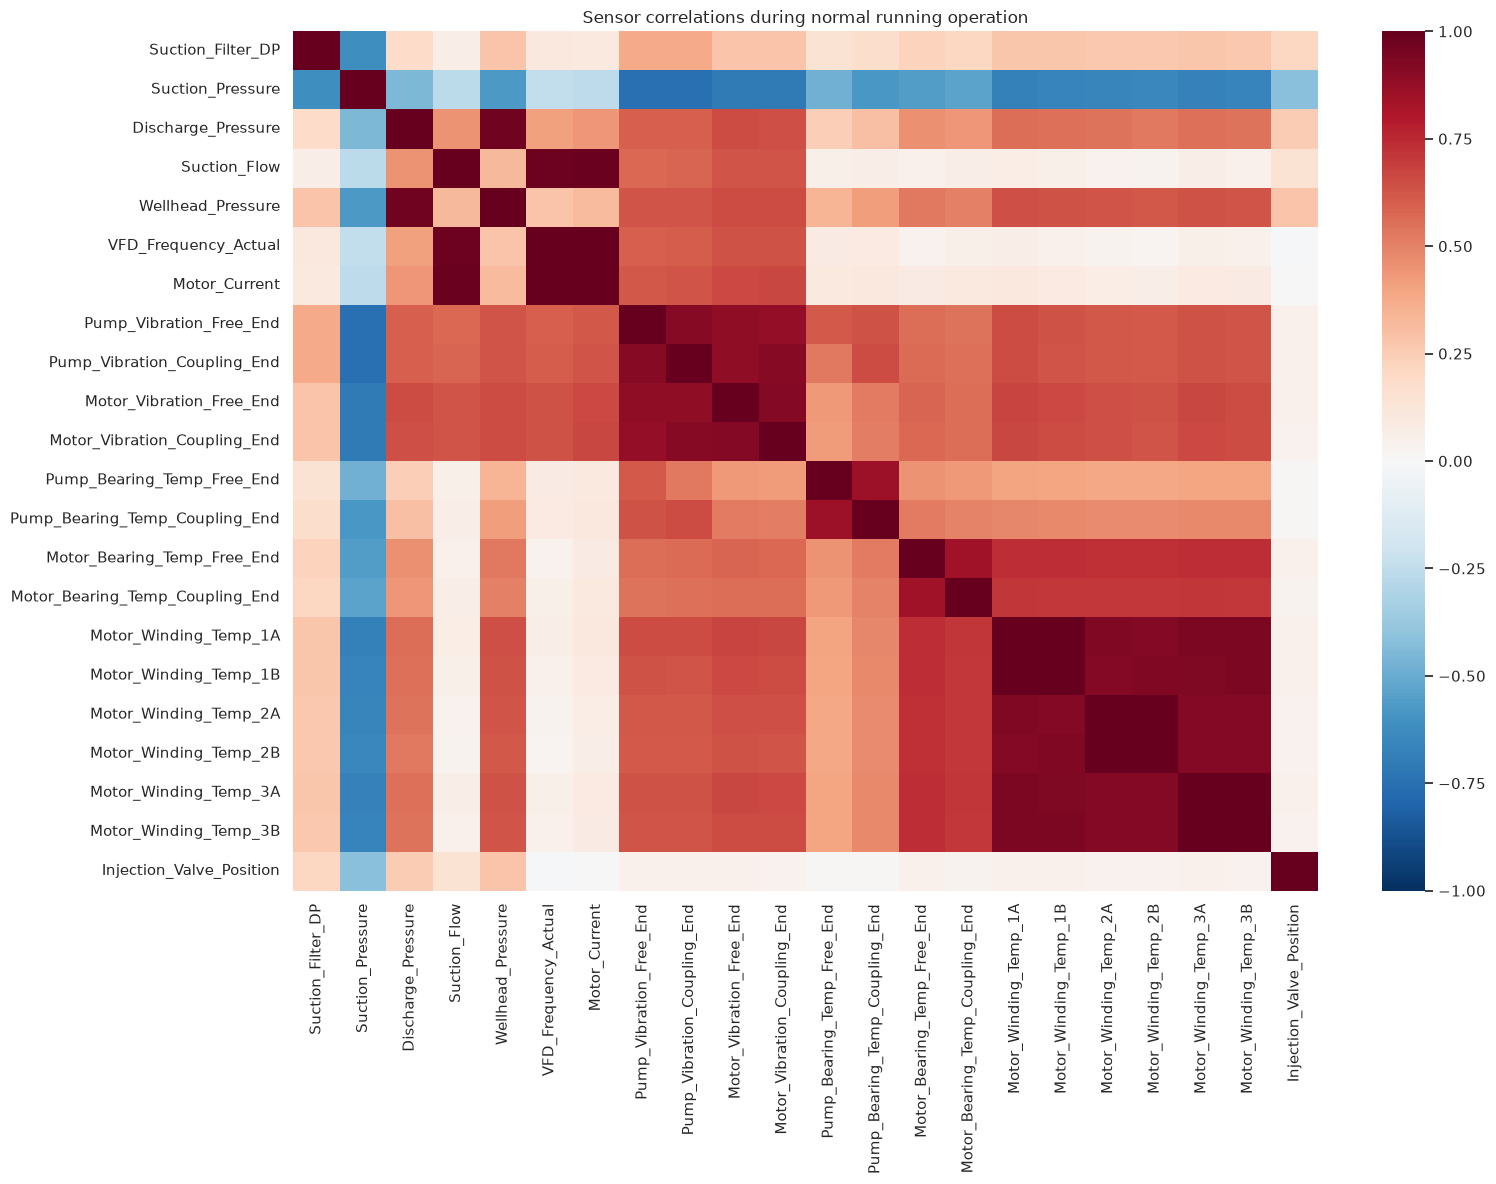

In [13]:
normal_running = df.loc[
    df["Pump_Running"].eq(1) & df["Failure_Code"].eq(0),
    sensor_columns,
]
correlation_sample = normal_running.sample(n=min(100_000, len(normal_running)), random_state=42)
correlation_matrix = correlation_sample.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Sensor correlations during normal running operation")
plt.tight_layout()
plt.show()

## Sensor Correlations During Normal Running Operation

The correlation matrix was calculated using records corresponding to normal running operation. This filter prevents stopped, transitional, and failure states from dominating the relationships between sensors.

The heatmap represents the linear correlation coefficient between each pair of variables:

- A value close to **+1** indicates a strong positive relationship.
- A value close to **−1** indicates a strong negative relationship.
- A value close to **0** indicates a weak linear relationship.

### Main observations

- The six motor winding temperature measurements are highly correlated. This is expected because all windings are exposed to similar electrical loads and thermal conditions.
- Pump and motor vibration measurements are strongly correlated, reflecting the mechanical coupling between the motor and pump.
- Motor bearing temperatures are strongly related to each other and to the winding temperatures.
- Discharge pressure and wellhead pressure show a strong positive correlation because pressure produced by the pump is transmitted through the injection system.
- VFD frequency and motor current are strongly correlated because higher rotational speed generally requires greater motor load.
- Suction pressure presents negative correlations with several process, vibration, and temperature variables.
- Injection valve position has relatively weak correlations with most sensors during normal operation.
- Suction filter differential pressure has weak correlations under normal conditions but may become more informative during filter-obstruction events.

### Machine-learning implications

The matrix reveals groups of variables that contain similar information. This condition is known as **multicollinearity**.

Strongly correlated variables do not necessarily need to be removed. Measurements from different physical locations may still help identify the location or progression of a fault. However, correlation should be considered during feature selection and model interpretation.

Tree-based models can generally handle correlated variables, although feature importance may be distributed among them. Linear models may require feature selection, regularization, or dimensionality-reduction techniques.

Finally, correlation does not imply causation. The observed relationships describe how the variables change together but do not prove that one variable directly causes another.

## 13. Compare sensor behavior across failure classes

The mean of each sensor is calculated for every failure class. Percentage changes relative to normal running operation show which sensors characterize each synthetic fault. Only running records are used to reduce shutdown-related distortion.

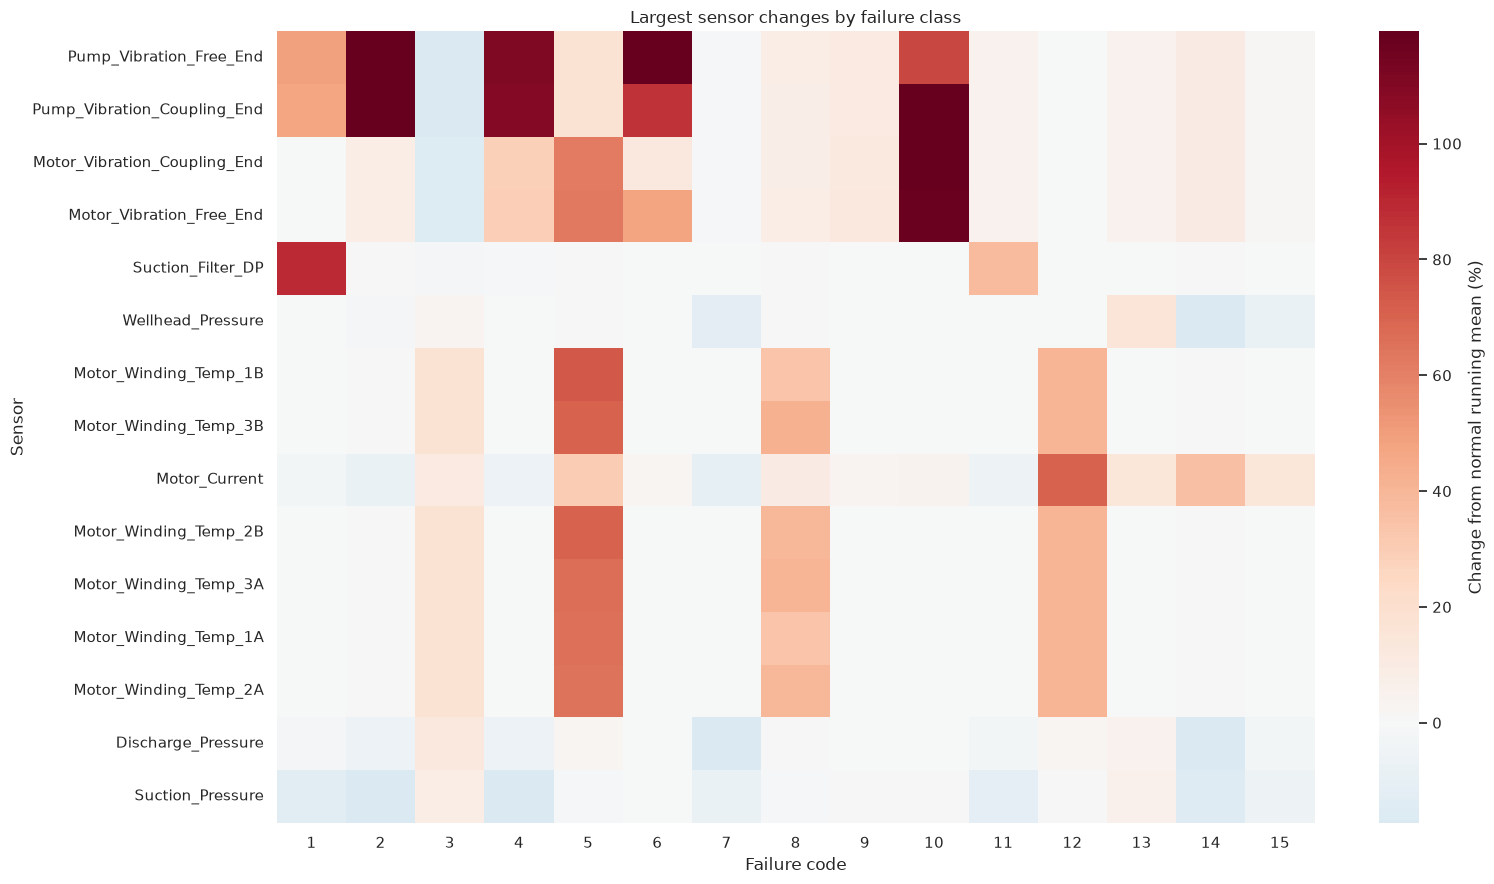

In [14]:
running_rows = df.loc[df["Pump_Running"].eq(1)]
mean_by_class = running_rows.groupby("Failure_Code")[sensor_columns].mean().transpose()
normal_mean = mean_by_class[0].replace(0, np.nan)
percent_change = mean_by_class.drop(columns=0).sub(normal_mean, axis=0).div(normal_mean, axis=0).mul(100)

relevant_sensors = percent_change.abs().max(axis=1).sort_values(ascending=False).head(15).index

plt.figure(figsize=(16, 9))
sns.heatmap(
    percent_change.loc[relevant_sensors],
    cmap="RdBu_r", center=0, robust=True,
    cbar_kws={"label": "Change from normal running mean (%)"},
)
plt.title("Largest sensor changes by failure class")
plt.xlabel("Failure code")
plt.ylabel("Sensor")
plt.tight_layout()
plt.show()

## Sensor Changes by Failure Class

This heatmap compares the mean sensor value for each failure class with the corresponding mean during normal running operation.

The percentage change was calculated relative to the normal operating baseline:

\[
\text{Percentage change} =
\frac{\text{Failure mean} - \text{Normal mean}}
{\text{Normal mean}} \times 100
\]

Red cells indicate increases relative to normal operation, while blue cells indicate decreases. Darker colors represent larger percentage changes.

### Main observations

- A clogged suction filter produces a strong increase in suction-filter differential pressure.
- Low suction pressure and cavitation reduce suction pressure and increase pump vibration.
- High discharge pressure increases both discharge pressure and related hydraulic variables.
- Motor overload increases motor current, motor vibration, and winding temperatures.
- Bearing and high-vibration failures create characteristic changes in vibration measurements.
- High winding temperature affects multiple winding measurements simultaneously.
- High motor current produces a strong current increase accompanied by winding-temperature increases.
- Wellhead-pressure failures produce changes in wellhead, discharge, and suction pressures.

These patterns demonstrate that the failure classes have different multivariable signatures. This is important because a machine-learning model can use the combined sensor behavior to distinguish between failure modes.

### Visualization limitations

The displayed sensors were selected according to the largest percentage changes. Consequently, some failure-specific variables are not visible. For example:

- Failure code 9 should be evaluated using bearing-temperature sensors.
- Failure codes 11 and 15 should be evaluated using suction-flow measurements.

Percentage changes must also be interpreted carefully when the normal baseline is close to zero. This particularly affects vibration variables, where a small absolute increase can produce a very large percentage change.

A more complete analysis should display the most relevant sensors for each individual failure class or use a standardized effect-size measurement.

## 14. Visualize one complete failure event

A complete event is plotted with context before and after the fault. This helps verify degradation, alarm or trip behavior, shutdown, and recovery. Change `SELECTED_EVENT_ID` to inspect another event.

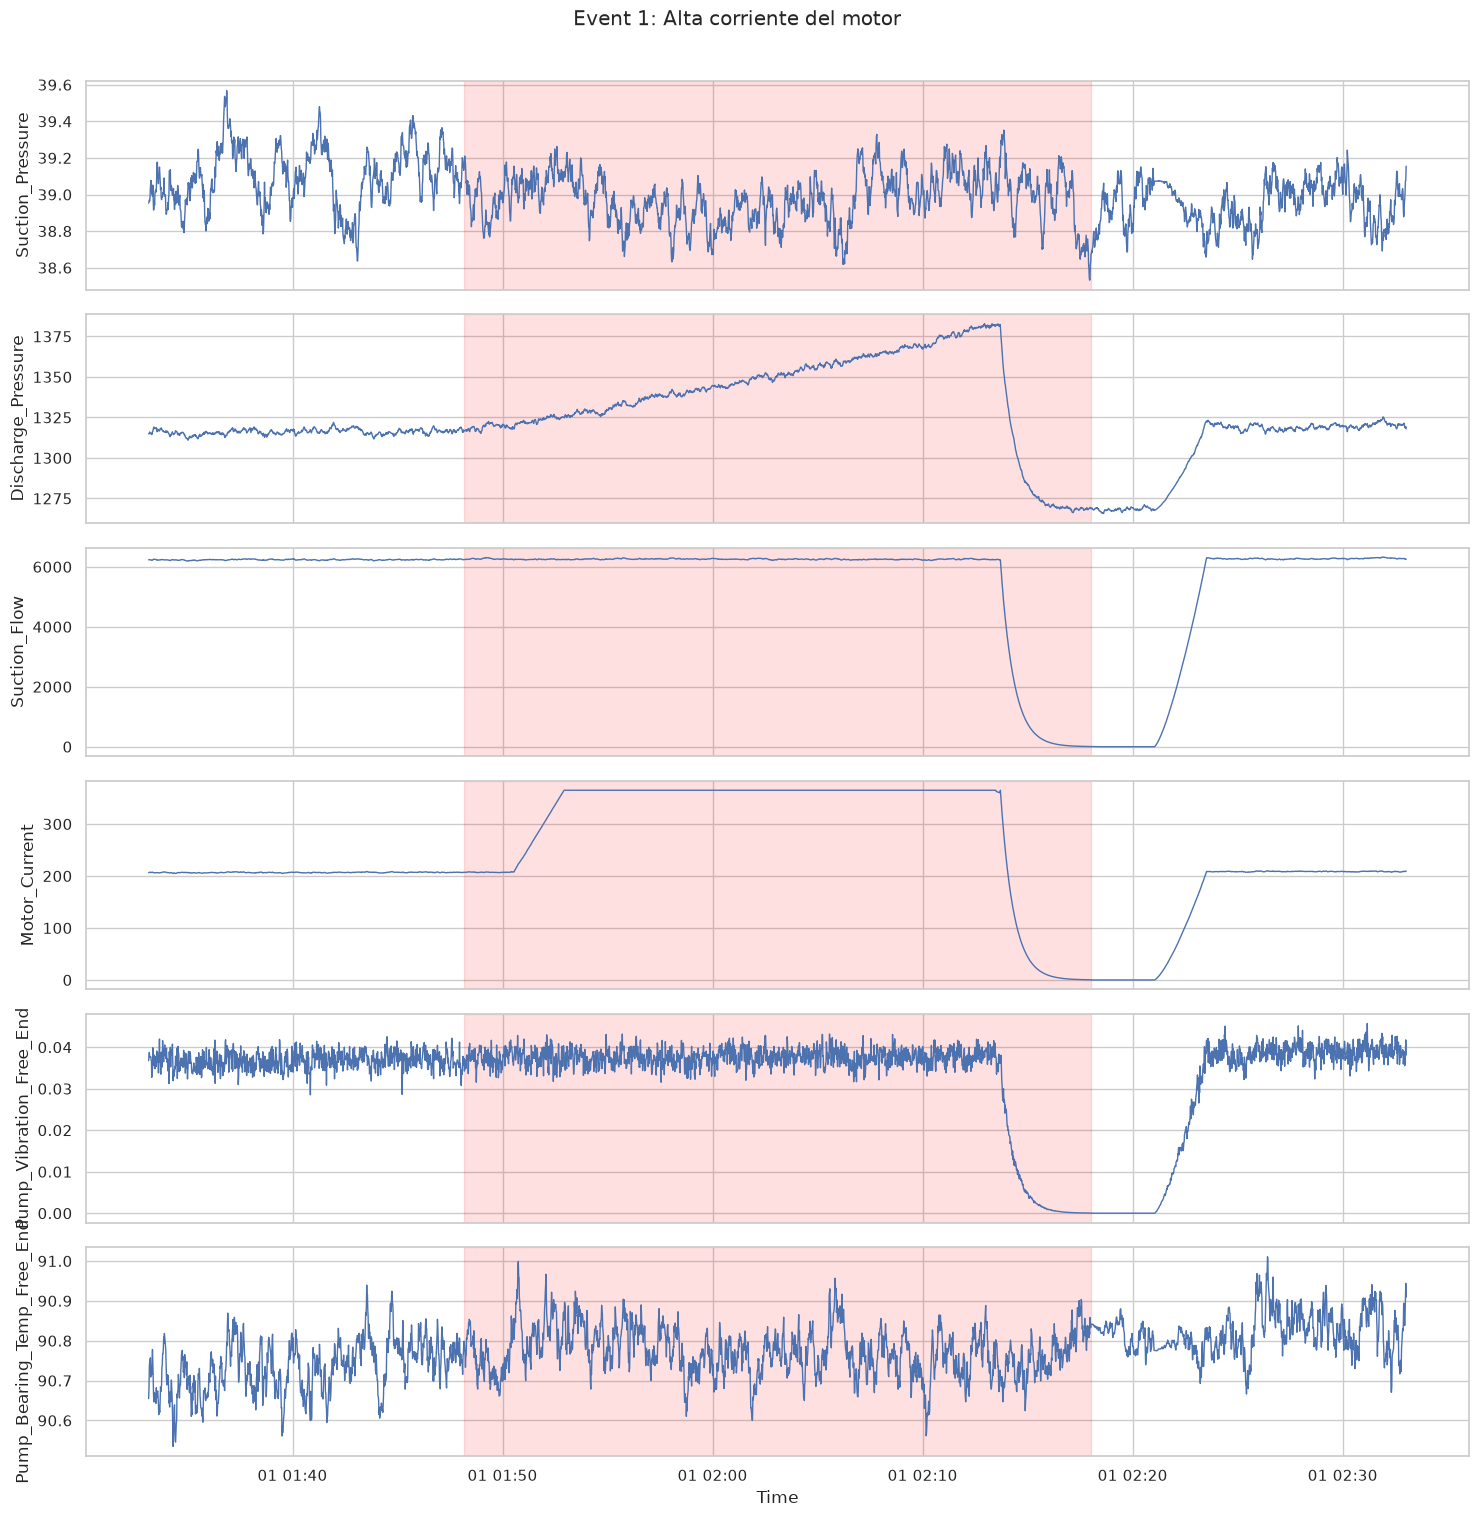

In [15]:
SELECTED_EVENT_ID = int(events.iloc[0]["Event_ID"])
selected_event = events.loc[events["Event_ID"].eq(SELECTED_EVENT_ID)].iloc[0]
window_start = selected_event["Start"] - pd.Timedelta(minutes=15)
window_end = selected_event["End"] + pd.Timedelta(minutes=15)
event_window = df.loc[df["Timestamp"].between(window_start, window_end)].copy()

candidate_signals = [
    "Suction_Pressure", "Discharge_Pressure", "Suction_Flow",
    "Motor_Current", "Pump_Vibration_Free_End",
    "Pump_Bearing_Temp_Free_End"
]
signals_to_plot = [signal for signal in candidate_signals if signal in df.columns]

fig, axes = plt.subplots(len(signals_to_plot), 1, figsize=(15, 2.5 * len(signals_to_plot)), sharex=True)
axes = np.atleast_1d(axes)
for axis, signal in zip(axes, signals_to_plot):
    axis.plot(event_window["Timestamp"], event_window[signal], linewidth=1)
    axis.axvspan(selected_event["Start"], selected_event["End"], color="red", alpha=0.12)
    axis.set_ylabel(signal)

fig.suptitle(f"Event {SELECTED_EVENT_ID}: {selected_event['Failure_Name']}", y=1.01)
plt.xlabel("Time")
plt.tight_layout()
plt.show()

## Temporal Analysis of a High-Motor-Current Event

This figure shows the temporal behavior of selected sensors before, during, and after an independent high-motor-current event.

The shaded red region represents the recorded failure-event interval. Event 1 is the event identifier (`Event_ID = 1`) and should not be confused with the failure code. The associated failure is high motor current (`Failure_Code = 12`).

### Event development

Before the event, the pump operates under stable conditions:

- Motor current is approximately 210 A.
- Suction flow is approximately 6,300 BPD.
- Pump vibration remains near 0.037 in/s.
- Discharge pressure is approximately 1,317 psig.

During the initial stage of the event, motor current increases progressively until it reaches approximately 365 A. It then remains at this abnormal level while discharge pressure gradually rises.

A protective trip subsequently stops the pump. Motor current, suction flow, and vibration decrease rapidly toward zero. Discharge pressure also falls as the pump loses hydraulic head.

After the stopped period, the pump restarts progressively. Current, flow, vibration, and discharge pressure return to their normal operating levels.

Suction pressure changes only slightly during the event. The pump-bearing temperature also remains relatively stable because this is primarily an electrical failure and the event duration is insufficient to generate a major bearing-temperature response.

### Predictive-maintenance interpretation

The progression before the trip provides a useful prediction window. A predictive model should detect the abnormal increase in motor current before the protective shutdown occurs.

Records containing the actual trip or the post-trip shutdown should not be used as evidence of early prediction, since the objective is to identify the developing failure before the trip.

Useful temporal features may include:

- Motor-current rolling mean
- Motor-current rate of change
- Time above the normal-current range
- Discharge-pressure trend
- Difference between current and its normal operating baseline
- Simultaneous changes across current, pressure, and flow

## 15. Identify data-leakage columns

Data leakage occurs when model inputs contain information that would not be available at prediction time or directly reveal the target. The columns below must not be used as predictive features. `Pump_Running` requires a separate design decision: it may be used as an operating filter or contextual variable, but stopped periods must not be mistaken for hydraulic failures.

In [16]:
leakage_columns = [
    "Failure_Code", "Failure_Name", "Event_ID", "Fault_Subtype",
    "Fault_Location", "Severity", "Alarm_Active",
    "Trip_Active", "Operating_State"
]

available_leakage_columns = [column for column in leakage_columns if column in df.columns]
candidate_model_features = [
    column for column in sensor_columns
    if column not in available_leakage_columns
]

print("Excluded leakage columns:")
print(available_leakage_columns)
print(f"\nCandidate physical sensor features: {len(candidate_model_features)}")
print(candidate_model_features)

Excluded leakage columns:
['Failure_Code', 'Failure_Name', 'Event_ID', 'Fault_Subtype', 'Fault_Location', 'Severity', 'Alarm_Active', 'Trip_Active', 'Operating_State']

Candidate physical sensor features: 22
['Suction_Filter_DP', 'Suction_Pressure', 'Discharge_Pressure', 'Suction_Flow', 'Wellhead_Pressure', 'VFD_Frequency_Actual', 'Motor_Current', 'Pump_Vibration_Free_End', 'Pump_Vibration_Coupling_End', 'Motor_Vibration_Free_End', 'Motor_Vibration_Coupling_End', 'Pump_Bearing_Temp_Free_End', 'Pump_Bearing_Temp_Coupling_End', 'Motor_Bearing_Temp_Free_End', 'Motor_Bearing_Temp_Coupling_End', 'Motor_Winding_Temp_1A', 'Motor_Winding_Temp_1B', 'Motor_Winding_Temp_2A', 'Motor_Winding_Temp_2B', 'Motor_Winding_Temp_3A', 'Motor_Winding_Temp_3B', 'Injection_Valve_Position']


## Feature Selection and Leakage Prevention

The preliminary feature-selection process identified 22 physical sensor variables as candidate model inputs.

Several metadata, state, event, and label columns were excluded because they contain information that directly or indirectly reveals the target condition.

### Excluded columns

- `Failure_Code` is the target variable that the model will attempt to predict.
- `Failure_Name` is a textual representation of the failure code.
- `Event_ID` identifies independent failure events and will be used for dataset splitting.
- `Fault_Subtype` and `Fault_Location` explicitly describe the simulated fault.
- `Severity` is derived from the known progression of the failure.
- `Alarm_Active` indicates that an alarm threshold has already been exceeded.
- `Trip_Active` indicates that the protective shutdown has already occurred.
- `Operating_State` includes states such as Degrading, Fault, and Tripped, which directly reveal the equipment condition.

Using these variables as model inputs would cause target leakage and produce overly optimistic evaluation results.

### Candidate sensor features

The remaining 22 variables represent physical measurements from the injection-pump system. They include:

- Hydraulic and process measurements
- VFD and motor measurements
- Pump and motor vibration
- Bearing temperatures
- Motor winding temperatures
- Injection-valve position

These variables could realistically be obtained from the control system or historian during actual operation.

### Variables retained for data management

`Timestamp` and `Event_ID` should be retained in the modeling dataset, but they should not be included in the model feature matrix:

- `Timestamp` is required for chronological ordering and temporal splitting.
- `Event_ID` is required to keep all records from the same event within a single dataset partition.

`Pump_Running` should be evaluated separately. Although it provides valid operational context, it may allow the model to distinguish post-trip shutdowns instead of detecting developing failures. The initial early-warning model will therefore use only the 22 physical sensor variables.

### Modeling implication

The model feature matrix can be defined as:

$$
X = \text{22 physical sensor variables}
$$

The target can be defined according to the modeling objective. For a multiclass classification model:

$$
y = \text{Failure Code}
$$

For an early-warning binary model:

$$
y =
\begin{cases}
0, & \text{normal operation} \\
1, & \text{developing failure}
\end{cases}
$$

Feature engineering must use only current and historical sensor information. Future measurements, alarms, trips, and post-failure states must not be included.

## 16. Initial conclusions and next steps

The exploratory data analysis confirms that the synthetic dataset contains **1,296,000 records covering 15 continuous days**, with a sampling interval of one second.

The dataset contains no missing values, duplicated timestamps, invalid timestamps, or unexpected temporal gaps. It includes **150 independent failure events**, distributed evenly across 15 failure classes, with 10 events per class.

A total of **22 physical sensor variables** were identified as candidate model features. Label, event, alarm, trip, severity, and operating-state variables were excluded from the feature set to prevent target leakage.

The analysis also shows that:

- Sensor behavior depends strongly on whether the pump is running, stopped, starting, or recovering.
- Failure classes present different hydraulic, electrical, mechanical, and thermal signatures.
- Some sensor groups are strongly correlated, particularly winding temperatures, bearing temperatures, and vibration measurements.
- Extreme sensor values generally correspond to simulated degradation, failure, or trip conditions and should not automatically be removed as outliers.
- Failure progression contains important temporal information that cannot be captured adequately using isolated one-second records.

### Modeling principles

The modeling workflow should follow these principles:

1. Separate physical sensor features from labels, metadata, alarms, trips, and post-event information.
2. Treat shutdown, startup, stopping, and recovery as operating states rather than independent equipment failures.
3. Create causal time-window features using only current and historical measurements, including mean, standard deviation, slope, minimum, maximum, and rate of change.
4. Keep all records belonging to the same `Event_ID` within a single dataset partition.
5. Divide normal operating records using complete chronological blocks.
6. Fit scalers, imputers, feature-selection methods, and other preprocessing steps using only the training set.
7. Evaluate each failure class using precision, recall, F1-score, and a confusion matrix.
8. Use metrics appropriate for class imbalance, such as macro F1-score, balanced accuracy, and precision-recall curves.
9. Compare model performance with and without highly correlated variables before removing sensors.
10. Ensure that early-warning models are evaluated using only information available before the alarm or trip.

### Next steps

The next phase should:

1. Define the first modeling objective: normal operation versus developing failure.
2. Define prediction windows and an early-warning horizon.
3. Engineer time-window features from the 22 physical sensors.
4. Create event-aware and chronological training, validation, and test partitions.
5. Train and evaluate a simple baseline model.
6. Extend the baseline to multiclass failure identification.
7. Validate the final methodology with real field data before production use.

Because the current dataset is synthetic, strong performance will demonstrate that the modeling pipeline works under controlled conditions. It will not, by itself, prove that the model generalizes to real industrial equipment. Real field data will require additional validation, adaptation, and potentially model retraining.